In [1]:
import os
import cv2
import numpy as np
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

IMAGE_SIZE = 64
BATCH_SIZE = 32
DATASET_PATH = r"C:\Users\Chair\Desktop\simpsons\simpsons_dataset"


print(os.listdir(DATASET_PATH)[:5])

['abraham_grampa_simpson', 'agnes_skinner', 'apu_nahasapeemapetilon', 'barney_gumble', 'bart_simpson']


In [3]:
%pip install tensorflow opencv-python scikit-learn numpy matplotlib

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 2.1/351.2 MB 15.8 MB/s eta 0:00:23
   - -------------------------------------- 14.7/351.2 MB 45.5 MB/s eta 0:00:08
   --- ------------------------------------ 32.2/351.2 MB 60.8 MB/s eta 0:00:06
   ----- ---------------------------------- 51.6/351.2 MB 70.4 MB/s eta 0:00:05
   -------- ------------------------------- 71.0/351.2 MB 76.1 MB/s eta 0:00:04
   ---------- ----------------------------- 90.4/351.2 MB 79.4 MB/s eta 0:00:04
   ------------ -------------------------- 111.7/351.2 MB 82.4 MB/s eta 0:00:03
   -------------- ------------------------ 131.9/351.2 MB 84.8 MB/s eta 0:00:03
   ---------------- ---------------------- 152.3/351.2 MB 86.7 MB/s eta 0:00:03
   ------------------- ------------------- 173.3/351.2 MB 88.4 MB/s eta 0:00:03
   --------------------- ----------------- 194.0/351.2 MB 89.7 MB/s eta 0:00:02
   ----------------------- --------------- 215.0/3

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [6]:
def load_dataset(dataset_path, image_size):
    images = []
    labels = []
    class_names = []

    for folder_name in sorted(os.listdir(dataset_path)):
        class_folder = os.path.join(dataset_path, folder_name)
        if not os.path.isdir(class_folder):
            continue

        class_index = len(class_names)
        loaded_count = 0

        for file_name in os.listdir(class_folder):
            image = cv2.imread(os.path.join(class_folder, file_name))
            if image is None:
                continue
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, (image_size, image_size))
            images.append(image)
            labels.append(class_index)
            loaded_count += 1

        if loaded_count > 0:
            class_names.append(folder_name)

    return np.array(images, dtype="uint8"), np.array(labels), class_names

images, labels, class_names = load_dataset(DATASET_PATH, IMAGE_SIZE)
num_classes = len(class_names)
print(images.shape, num_classes)

#step 2

(20933, 64, 64, 3) 42


In [7]:
train_images, test_images, train_labels, test_labels = train_test_split(
    images, labels, test_size=0.2, stratify=labels, random_state=42
)

train_labels_onehot = keras.utils.to_categorical(train_labels, num_classes)
test_labels_onehot = keras.utils.to_categorical(test_labels, num_classes)

In [8]:
def build_pretrained_model(image_size, num_classes):
    base_model = keras.applications.MobileNetV2(
        input_shape=(image_size, image_size, 3),
        include_top=False,
        weights="imagenet",
    )
    base_model.trainable = False   # freeze the ImageNet features

    inputs = keras.Input(shape=(image_size, image_size, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomTranslation(0.1, 0.1)(x)
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)   # MobileNetV2 wants [-1, 1]
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return keras.Model(inputs, outputs)

model = build_pretrained_model(IMAGE_SIZE, num_classes)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

C:\Users\Chair\AppData\Local\Temp\ipykernel_37132\4128055915.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 42)             │        53,802 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,311,786 (8.82 MB)

 Trainable params: 53,802 (210.16 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
history = model.fit(
    train_images, train_labels_onehot,
    validation_data=(test_images, test_labels_onehot),
    epochs=15,
    batch_size=BATCH_SIZE,
)

predictions = np.argmax(model.predict(test_images), axis=1)
print(classification_report(test_labels, predictions, target_names=class_names))
print(confusion_matrix(test_labels, predictions))

Epoch 1/15
524/524 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.2304 - loss: 2.9008 - val_accuracy: 0.3305 - val_loss: 2.3980
Epoch 2/15
524/524 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.3348 - loss: 2.4158 - val_accuracy: 0.3714 - val_loss: 2.2640
Epoch 3/15
524/524 ━━━━━━━━━━━━━━━━━━━━ 18s 33ms/step - accuracy: 0.3607 - loss: 2.2878 - val_accuracy: 0.3855 - val_loss: 2.2205
Epoch 4/15
524/524 ━━━━━━━━━━━━━━━━━━━━ 18s 33ms/step - accuracy: 0.3757 - loss: 2.2193 - val_accuracy: 0.4003 - val_loss: 2.1669
Epoch 5/15
524/524 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.3772 - loss: 2.1916 - val_accuracy: 0.4012 - val_loss: 2.1556
Epoch 6/15
524/524 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.3855 - loss: 2.1682 - val_accuracy: 0.4048 - val_loss: 2.1421
Epoch 7/15
524/524 ━━━━━━━━━━━━━━━━━━━━ 18s 33ms/step - accuracy: 0.3874 - loss: 2.1603 - val_accuracy: 0.4129 - val_loss: 2.1394
Epoch 8/15
524/524 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.3920 - loss: 2.1315 - 

c:\Users\Chair\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Chair\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Chair\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


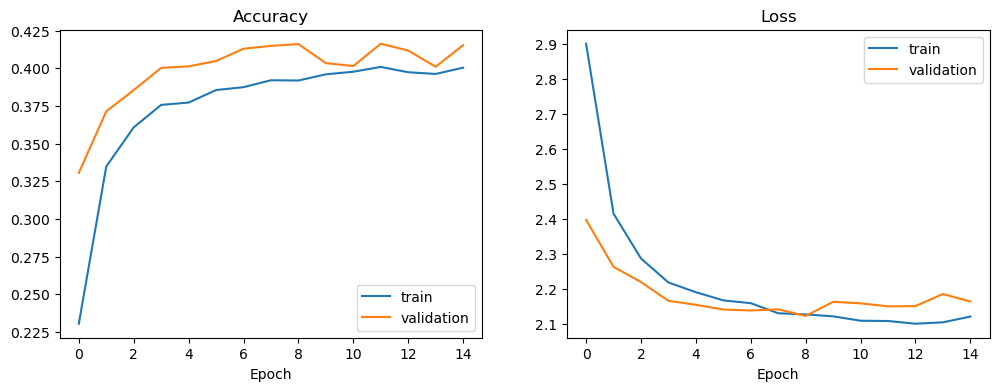

In [10]:
#plot it
import matplotlib.pyplot as plt

def plot_history(history):
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history["accuracy"], label="train")
    axes[0].plot(history.history["val_accuracy"], label="validation")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history.history["loss"], label="train")
    axes[1].plot(history.history["val_loss"], label="validation")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.show()

plot_history(history)